# Class 11: Linear models 

This class notebook is designed to let you practice the basics of modelling simple datasets. The datasets are small and simple compared to the project datasets. This is so that you can learn the concepts of data modelling without the additional burden of cleaning and manipulating large, messy datasets. 

There are three questions in this notebook

1. **Horned lizards**: Modelling the relationship between horn length and predation (a single categorical variable)
2. **Guinea pig tooth growth**: Modelling the relationship between guinea pig tooth growth, dose of vitamin C (a single categorical variable) and method of delivery (a single categorical variable).
3. **Earthworms in North America**: Modelling the relationship between the number of earthworm species and soil nitrogen content (two numerical variables).

Everything you need to complete these analyses is covered in today's lecture and the accompanying workflow notebooks. The workflow notebooks work through the examples in the lecture in more detail. You should make use of those as a reference for completing the questions in this notebook.

<div class="alert alert-info">
The answers to the questions below are given in blue boxes. These are there to help you write the correct code.
</div>

## Imports

In [1]:
import pandas as pd
import seaborn as sns
from statsmodels.formula.api import ols

# **Question 1**: Do the horns of horned-lizards protect them from predation?

<div>
<img src="Images/lizard.jpg" width='40%'/>
</div>

The horned lizard *Phrynosoma macallii* is named for the fringe of horns surrounding the head. What are the horns for? One idea proposed by researchers (Young et al. 2004) is that they offer some protection against being eaten by one of their main predators, the loggerhead shrike, *Lanius ludovicianus*. The shrike skewers the lizard on thorns or barbed wire to save for later eating.

![](Images/shrike.jpg)

The researchers measured the horn lengths of horned lizards that had not been predated (and hence were alive and free at some point in time) and the horn lengths of lizards that had been predated (and hence were skewered and dead at the same point in time). If their hypothesis were true then we might expect to see a difference in mean horn lengths between living and killed lizards. But if their hypothesis is wrong then we might expect to see no such difference.

The data collected by the researchers are in the file `../Datasets/horned_lizards.csv`.

<div class="alert alert-warning">

Use the [workflow_ground_finch.ipynb](workflow_ground_finch.ipynb) notebook to help you answer this question.
</div>

- Read in the data and print it to see what it looks like.

In [7]:
lizards = pd.read_csv('../Datasets/horned_lizards.csv')
lizards

,predation,length
0,living,25.2
1,living,26.9
2,living,26.6
3,living,25.6
4,living,25.7
5,living,25.9
6,living,27.3
7,living,25.1
8,living,30.3
9,living,25.6


- Use an appropriate graph to visually examine the relationship between horn length and predation status. 

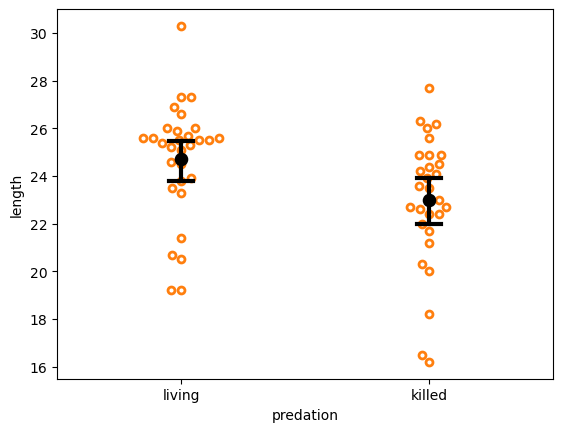

In [9]:
ax = sns.pointplot(data=lizards, y='length', x='predation', capsize=.1, color="k", linestyle="none", marker="o", linewidth=3)
sns.swarmplot(data=lizards, y='length', x='predation', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2);


- State the null hypothesis. 

> Mean horn lengths of predated and non-predated horned lizards are the same.

- Write the model formula for the relationship between horn length and predation status.
- Fit the model and output the summary table.

<div class="alert alert-info">

Answers for the difference in horn length:

- coef = 1.7
- *t* = 2.6
- *P* = 0.013
- 95% CI: [0.38, 3.05] mm
</div>

In [14]:
formula = 'length ~ predation'
fit = ols(formula, lizards).fit()
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,22.9867,0.472,48.704,0.000,22.042,23.931
predation[T.living],1.7100,0.667,2.562,0.013,0.374,3.046


- Report the outcome of the test as you would in a scientific report or paper. This means report the estimate of the difference (with error), the value of *t* and the degrees of freedom (i.e., *t~n~*) and *P*.

> Mean horn length of horned lizards that lived is 1.7 mm longer (95%CI [0.4, 3.0] mm) than that of lizards that were killed ($t_{58}=$ 2.6, *p* = 0.013).

# **Question 2:** Does dose and delivery method of vitamin C affect guinea pig teeth growth

![](Images/guinea_pig_teeth.jpg)

Scientists wanted to understand if the dose and the delivery method of vitamin C affected the growth of guinea pig teeth.

The dataset contains the result of an experiment on the growth of teeth measured in 10 guinea pigs at two dose levels of vitamin C (1 and 2 mg/day) delivered via two methods: orange juice or water. The data collected by the researchers are in the file `../Datasets/guinea_pig_tooth_growth.csv`.

<div class="alert alert-warning">

Use the [workflow_two_finch_species.ipynb](workflow_two_finch_species.ipynb) notebook to help you answer this question.
</div>

- Read in the data and print it to see what it looks like.

In [20]:
gp = pd.read_csv('../Datasets/guinea_pig_tooth_growth.csv')
gp

,length,method,dose
0,16.5,water,1
1,16.5,water,1
2,15.2,water,1
3,17.3,water,1
4,22.5,water,1
5,17.3,water,1
6,13.6,water,1
7,14.5,water,1
8,18.8,water,1
9,15.5,water,1


- As `dose` only has two levels (1 and 2 mg/day), explicitly set it as categorical.

In [22]:
gp['dose'] = gp['dose'].astype('category')

- Use an appropriate graph to visually examine the relationships between tooth length, method of delivery and vitamin C dose. 

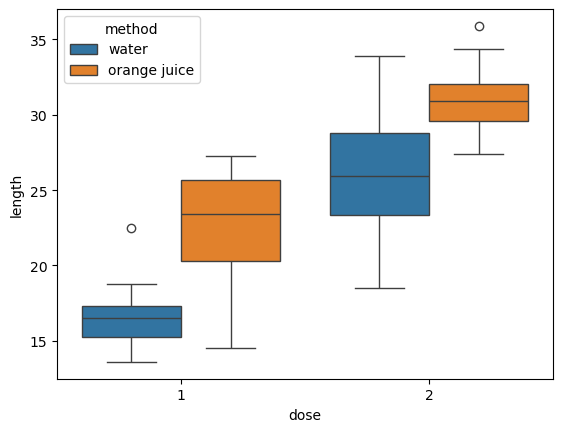

In [24]:
sns.boxplot(data=gp, x='dose', y='length', hue='method');

- Describe what the data show about the relationship between tooth length, dose and method of delivery.

> Increasing dose increases tooth length. Orange juice has a larger effect on tooth length than water at both doses.

- Write the model formula for the relationship between tooth length, method and dose. Explore whether your model should include an interaction term.
- Fit the model and output the summary table and *P*-values.

<div class="alert alert-info">

Answers for dose:

- coef = 8.9 mm
- *t* = 7.9
- *P* = 1.9 x 10<sup>-9</sup>
- 95% CI: [6.6, 11.1] mm

Answers for method of delivery (absolute values):

- coef = 5.4 mm
- *t* = 4.8
- *P* = 2.4 x 10<sup>-5</sup>
- 95% CI: [3.1, 7.7] mm

</div>

In [29]:
# with an interaction

formula = 'length ~ C(dose) * method'
fit = ols(formula, gp).fit()
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,22.7000,1.137,19.969,0.000,20.395,25.005
C(dose)[T.2],8.3600,1.608,5.200,0.000,5.100,11.620
method[T.water],-5.9300,1.608,-3.689,0.001,-9.190,-2.670
C(dose)[T.2]:method[T.water],1.0100,2.274,0.444,0.660,-3.601,5.621


In [30]:
# without an interaction

formula = 'length ~ C(dose) + method'
fit = ols(formula, gp).fit()
print(fit.pvalues)
fit.summary().tables[1]

Intercept          1.509447e-23
C(dose)[T.2]       1.945877e-09
method[T.water]    2.419969e-05
dtype: float64


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,22.4475,0.974,23.053,0.000,20.475,24.420
C(dose)[T.2],8.8650,1.124,7.884,0.000,6.587,11.143
method[T.water],-5.4250,1.124,-4.825,0.000,-7.703,-3.147


- In order to interpret the summary table you need to know the reference levels for each categorical variable. Note these below.

> - dose: 1 mg/d
> - method: orange juice

- Report the outcome of the test as you would in a scientific report or paper. This means reporting the estimates (with errors), the values of *t* and the degrees of freedom (i.e., *t~n~*) and the values of *P*. Also report *t*, *P* and the 95% CI for the interaction between dose and method.

> Orange juice as a method of delivering vitamin C significantly increases guinea pig tooth growth by 5.4 mm compared to water (95% CI: [3.1, 7.7] mm, $t_{36}=4.9$, $P=2.4\times 10^{-5}$). Increasing the dose from 1 to 2 mg/d significantly increases tooth growth by 8.9 mm (95% CI: [6.6, 11.1] mm, $t_{36}=7.9$, $P=1.9\times 10^{-9}$). There is no interaction between method of delivery and dose (95% CI: [-5.6, 3.6] mm, $t_{36}=2.3$, $P=0.66$).

# **Question 3:** Is soil nitrogen content affected by the number of different earthworm species?

<div>
<img src="Images/worms.jpg" width='50%' title=""/>
</div>

The forests of northern USA and Canada have no native earthworms. However, earthworms have been introduced by humans and are dramatically changing the soil. To examine if earthworms are changing the nitrogen content of soil, scientists (Gundale et al. 2005) measured nitrogen content and the number of different species of earthworms in 39 hardwood forests in Michigan. 


The data are in the file `../Datasets/earthworms.csv`. Nitrogen content is recorded as a percentage.

<div class="alert alert-warning">

Use the [rattlesnakes_workflow.ipynb](workflow_rattlesnakes.ipynb) notebook to help you answer this question.
</div>

- Read in the data and print it to see what it looks like.

In [39]:
worms = pd.read_csv('../Datasets/earthworms.csv')
worms

,NumWormSpecies,nitrogen
0,0,0.22
1,0,0.19
2,0,0.16
3,0,0.08
4,1,0.33
5,1,0.30
6,1,0.26
7,1,0.24
8,1,0.20
9,1,0.18


- Use an appropriate graph to visually examine the relationship between nitrogen content and number of worm species. 

Hint: The number of worm species should be treated as a numerical variable NOT as a categorical variable.

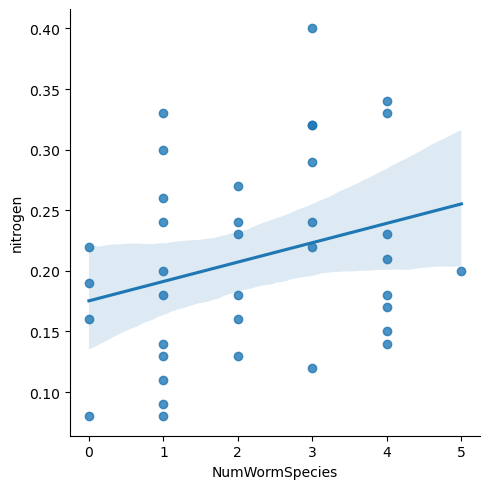

In [41]:
sns.lmplot(x='NumWormSpecies', y='nitrogen', data=worms);

- State the null hypothesis regarding the relationship between nitrogen content and number of worm species. 

> The slope of the relationship between number of earthworm species and soil nitrogen content is zero.

- Write the model formula for the relationship between number of earthworm species and soil nitrogen content.
- Fit the model and test the null hypothesis.
<div class="alert alert-info">

Answer
- coef = 0.016
- *t* = 1.76
- *P* = 0.088
- 95% CI: [-0.002, 0.034] mm

</div>

In [47]:
formula = 'nitrogen ~ NumWormSpecies'
fit = ols(formula, worms).fit()
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,0.1753,0.024,7.389,0.000,0.127,0.223
NumWormSpecies,0.0160,0.009,1.756,0.088,-0.002,0.034


- Report the outcome of the test as you would in a scientific report or paper.

> There is no statistically significant relationship between the number of species of earthworms and soil nitrogen content in North American forests ($t_{36}=$ 1.8, *p* = 0.088).